# Étape 1 — Chargement et analyse exploratoire des données

Cette analyse décrit le jeu de données et explore les associations avec `Mental_Health_Risk`. Elle ne supprime, ne remplace et n'impute aucune valeur. Les résultats décrivent des associations et ne démontrent pas de causalité.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

student_df = pd.read_csv('../data/raw/student_mental_health.csv')
sns.set_theme(style='whitegrid')

## 1. Structure du jeu de données

Aperçu, dimensions, types et informations non nulles des colonnes.

In [2]:
display(student_df.head())
print(f'Dimensions : {student_df.shape[0]} lignes × {student_df.shape[1]} colonnes')
student_df.info()
display(student_df.dtypes.rename('type').to_frame())

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


Dimensions : 2000 lignes × 17 colonnes
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attend

,type
Student_ID,str
Age,int64
Gender,str
Year_of_Study,int64
Sleep_Hours,float64
Study_Hours_Per_Week,float64
GPA,float64
Social_Media_Hours,float64
Screen_Time_Hours,float64
Physical_Activity,str


## 2. Valeurs manquantes, doublons et cohérence

Les contrôles de plage utilisent les règles de domaine usuelles visibles dans les variables (par exemple GPA sur 0–4 et présence sur 0–100). Les catégories sont affichées pour permettre de repérer des libellés incohérents. Les valeurs sont uniquement signalées, pas corrigées.

In [3]:
missing_summary = pd.DataFrame({
    'missing_count': student_df.isna().sum(),
    'missing_percent': (student_df.isna().mean() * 100).round(2)
})
display(missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_count', ascending=False))

print('Lignes entièrement dupliquées :', student_df.duplicated().sum())
if 'Student_ID' in student_df.columns:
    print('Student_ID dupliqués :', student_df['Student_ID'].duplicated().sum())

range_checks = {
    'Year_of_Study': (1, 5),
    'GPA': (0, 4),
    'Financial_Stress': (1, 10),
    'Family_Support': (1, 10),
    'Attendance_Rate': (0, 100)
}
for column, (minimum, maximum) in range_checks.items():
    if column in student_df.columns:
        values = student_df[column]
        invalid = values.notna() & ~values.between(minimum, maximum)
        print(f'{column} hors de [{minimum}, {maximum}] : {invalid.sum()}')

categorical_columns = [
    column for column in student_df.columns
    if column not in student_df.select_dtypes(include='number').columns
    and column != 'Student_ID'
]
for column in categorical_columns:
    print(f'\nValeurs observées pour {column} :')
    print(sorted(student_df[column].dropna().astype(str).unique().tolist()))

,missing_count,missing_percent
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


Lignes entièrement dupliquées : 0
Student_ID dupliqués : 0
Year_of_Study hors de [1, 5] : 0
GPA hors de [0, 4] : 0
Financial_Stress hors de [1, 10] : 0
Family_Support hors de [1, 10] : 0
Attendance_Rate hors de [0, 100] : 0

Valeurs observées pour Gender :
['Female', 'Male', 'Non-binary']

Valeurs observées pour Physical_Activity :
['High', 'Low', 'Moderate']

Valeurs observées pour Part_Time_Job :
['No', 'Yes']

Valeurs observées pour Diet_Quality :
['Average', 'Good', 'Poor']

Valeurs observées pour Previous_Mental_Health_History :
['No', 'Yes']

Valeurs observées pour Mental_Health_Risk :
['High', 'Low', 'Medium']


## 3. Statistiques descriptives

Les statistiques numériques et catégorielles sont présentées séparément.

In [4]:
display(student_df.describe(include='number').T)
display(student_df.describe(include='all').T)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,2000,2000,STU0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2000.0,NaN,NaN,NaN,21.1315,2.139275,17.0,20.0,21.0,23.0,29.0
Gender,2000,3,Female,971,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year_of_Study,2000.0,NaN,NaN,NaN,2.63,1.316802,1.0,1.0,2.0,4.0,5.0
Sleep_Hours,1938.0,NaN,NaN,NaN,6.758875,1.127072,3.3,6.0,6.7,7.6,10.0
Study_Hours_Per_Week,2000.0,NaN,NaN,NaN,19.9979,5.719274,2.4,16.0,19.8,24.0,38.3
GPA,1962.0,NaN,NaN,NaN,2.562503,0.343993,1.5,2.32,2.56,2.79,3.66
Social_Media_Hours,1942.0,NaN,NaN,NaN,6.013955,1.153422,2.1,5.225,6.0,6.7,10.0
Screen_Time_Hours,2000.0,NaN,NaN,NaN,8.5485,1.657571,3.3,7.4,8.5,9.7,14.0
Physical_Activity,2000,3,Moderate,906,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Valeurs aberrantes

La règle IQR repère des valeurs inhabituelles, mais ne prouve pas qu'elles sont erronées. Les bornes et nombres ci-dessous sont calculés sans remplacer ni supprimer les observations. `Year_of_Study` est une catégorie ordonnée et n'est pas traitée comme une mesure continue ici.

In [5]:
numeric_columns = student_df.select_dtypes(include='number').columns.tolist()
continuous_columns = [column for column in numeric_columns if column != 'Year_of_Study']

outlier_rows = []
for column in continuous_columns:
    values = student_df[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = values[(values < lower_bound) | (values > upper_bound)]
    outlier_rows.append({
        'column': column,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'outlier_count': len(outliers)
    })
display(pd.DataFrame(outlier_rows).set_index('column'))

,lower_bound,upper_bound,outlier_count
column,,,
Age,15.5000,27.5000,4
Sleep_Hours,3.6000,10.0000,2
Study_Hours_Per_Week,4.0000,36.0000,7
GPA,1.6150,3.4950,9
Social_Media_Hours,3.0125,8.9125,20
Screen_Time_Hours,3.9500,13.1500,7
Financial_Stress,0.1500,11.7500,0
Family_Support,0.7500,12.3500,0
Attendance_Rate,65.7500,104.5500,12


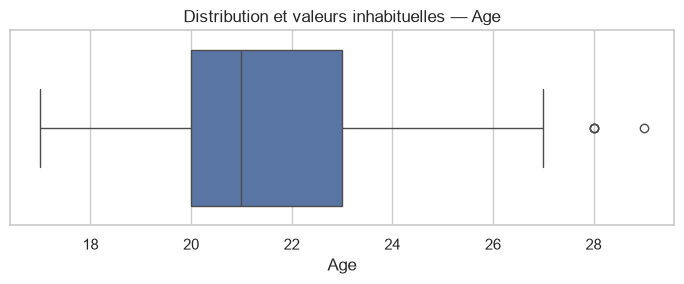

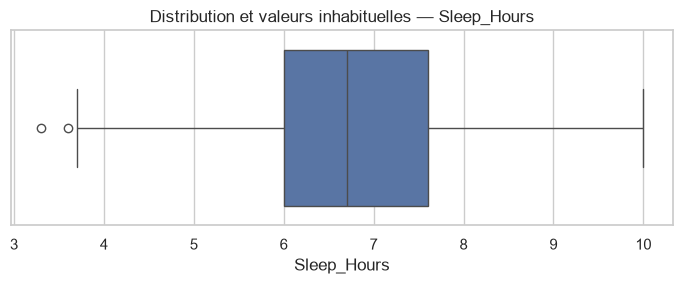

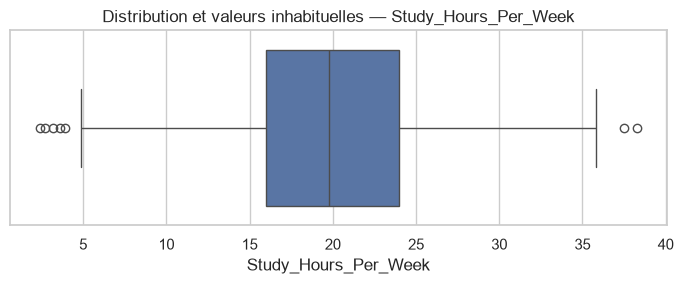

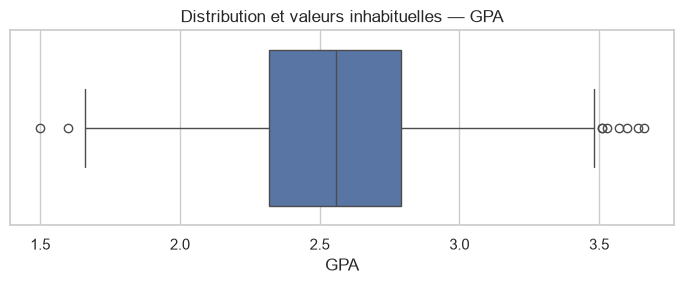

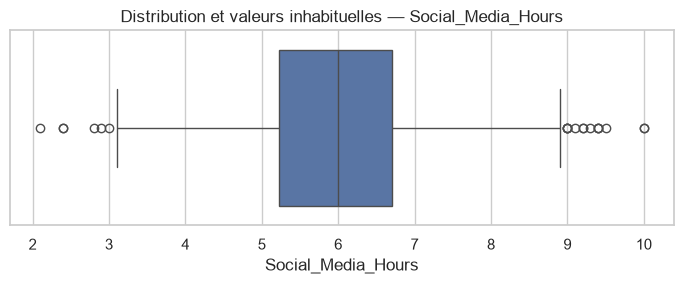

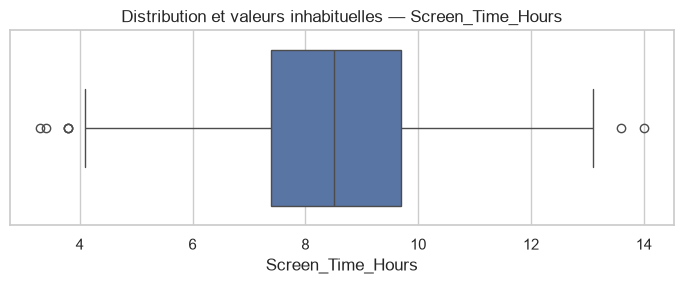

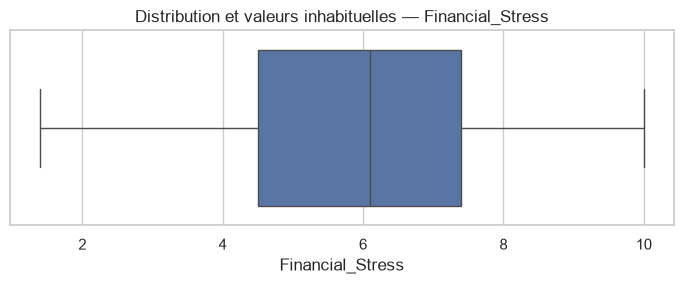

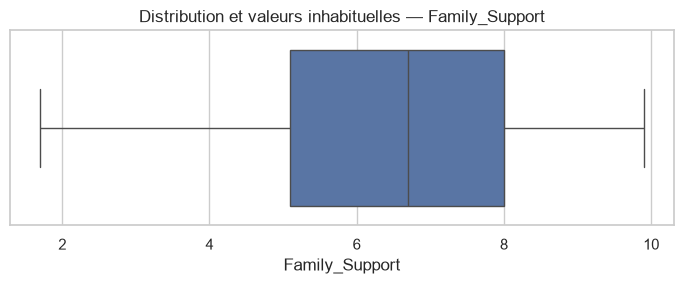

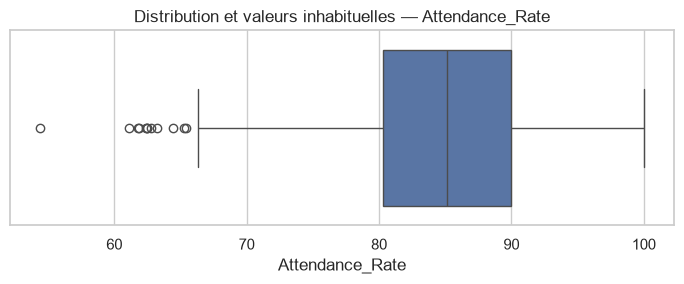

In [6]:
for column in continuous_columns:
    plt.figure(figsize=(7, 3))
    sns.boxplot(data=student_df, x=column)
    plt.title(f'Distribution et valeurs inhabituelles — {column}')
    plt.tight_layout()
    plt.show()
    plt.close()

## 5. Distribution de la variable cible

Les effectifs et pourcentages permettent d'évaluer visuellement et numériquement l'équilibre des classes.

,count,percent
Mental_Health_Risk,,
Low,660,33.0
Medium,660,33.0
High,680,34.0


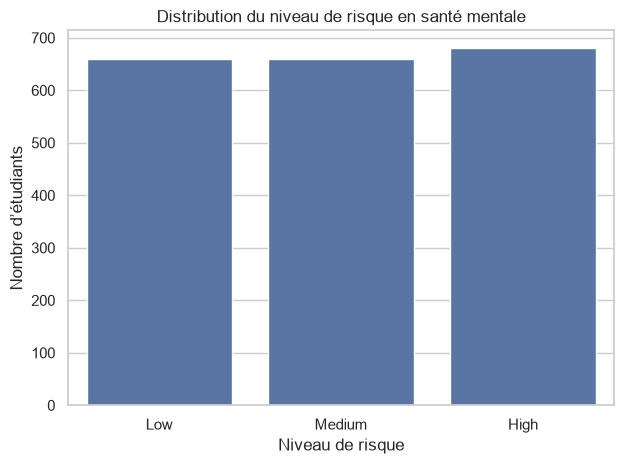

In [7]:
target = 'Mental_Health_Risk'
risk_order = ['Low', 'Medium', 'High']
risk_counts = student_df[target].value_counts().reindex(risk_order, fill_value=0)
risk_percentages = (student_df[target].value_counts(normalize=True).reindex(risk_order, fill_value=0) * 100).round(1)
display(pd.DataFrame({'count': risk_counts, 'percent': risk_percentages}))

sns.countplot(data=student_df, x=target, order=risk_order)
plt.title('Distribution du niveau de risque en santé mentale')
plt.xlabel('Niveau de risque')
plt.ylabel('Nombre d’étudiants')
plt.tight_layout()
plt.show()

## 6. Relations entre les variables explicatives et le risque

Les boîtes à moustaches comparent les distributions numériques par niveau de risque. Les barres empilées comparent les proportions de risque pour chaque catégorie; les valeurs manquantes sont exclues de chaque graphique.

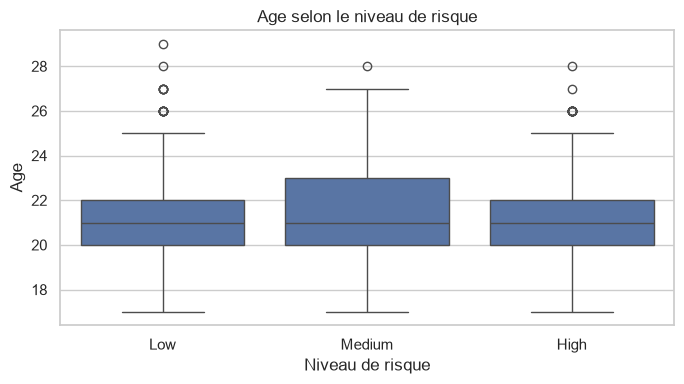

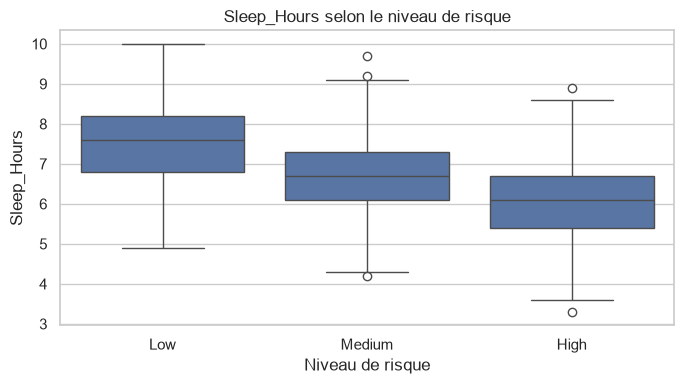

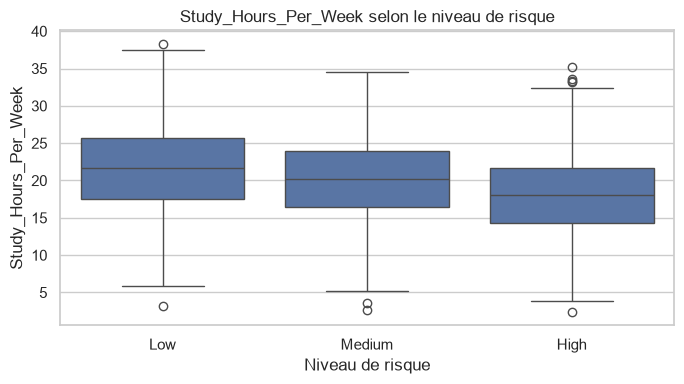

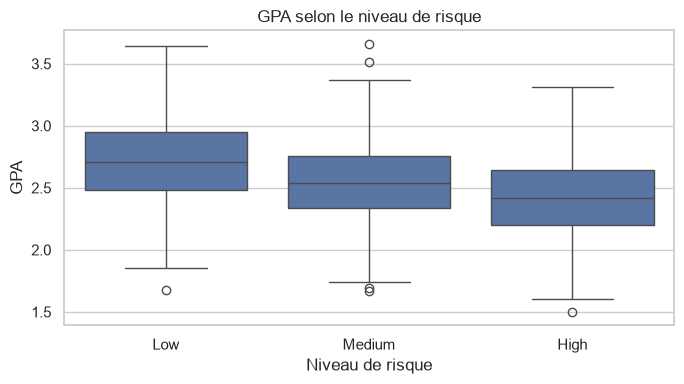

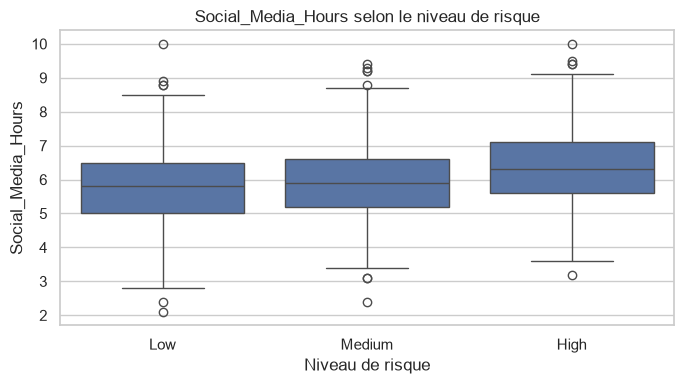

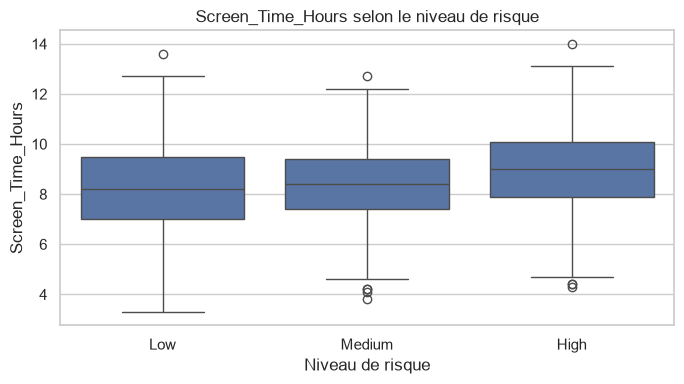

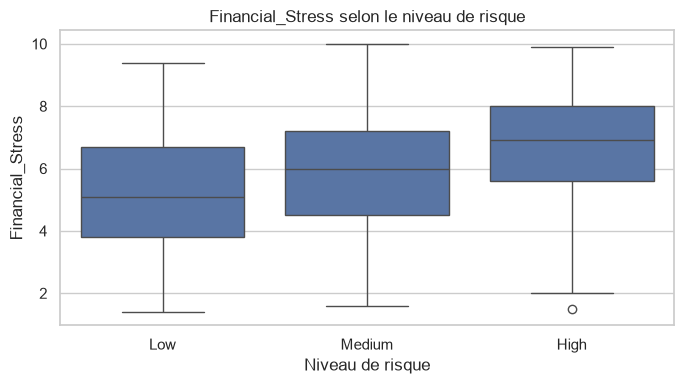

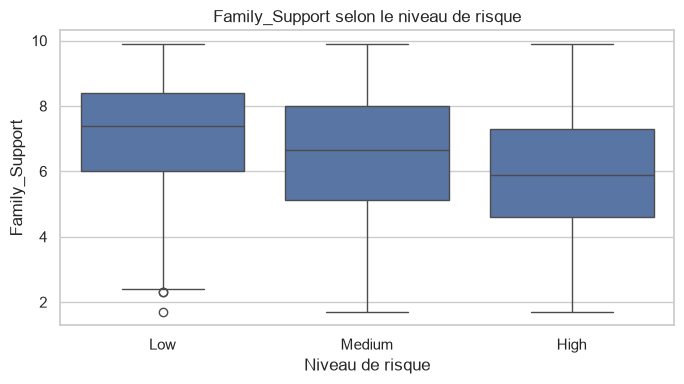

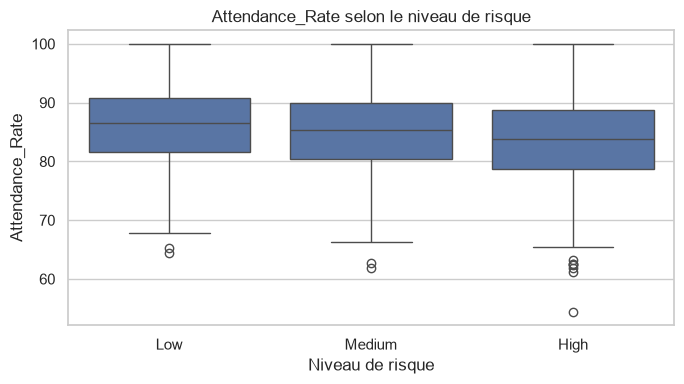

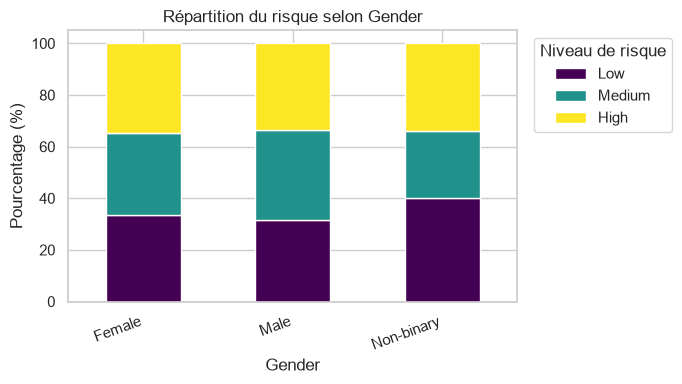

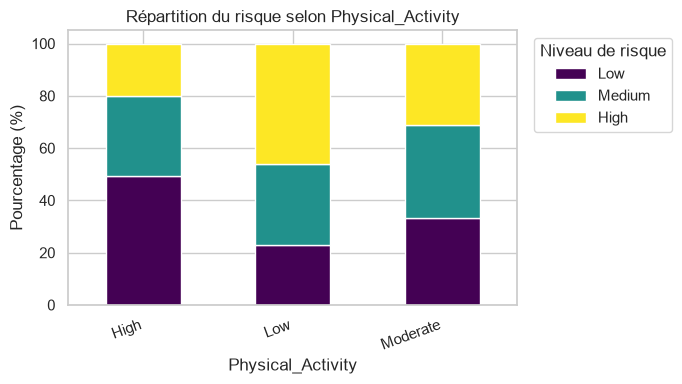

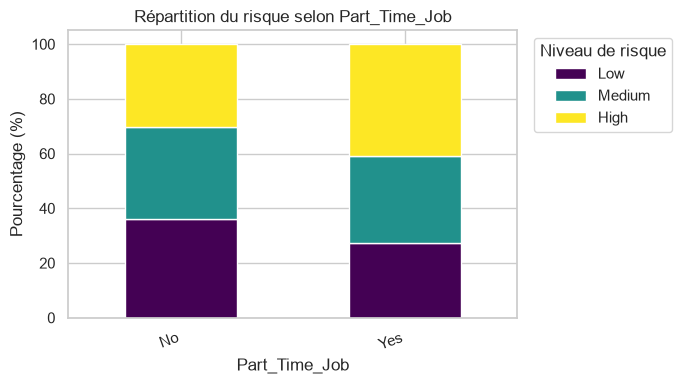

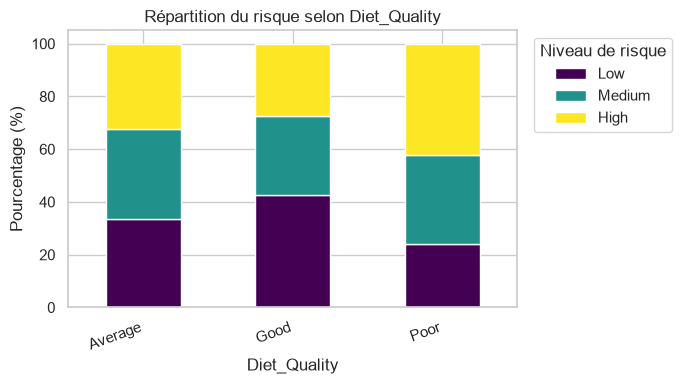

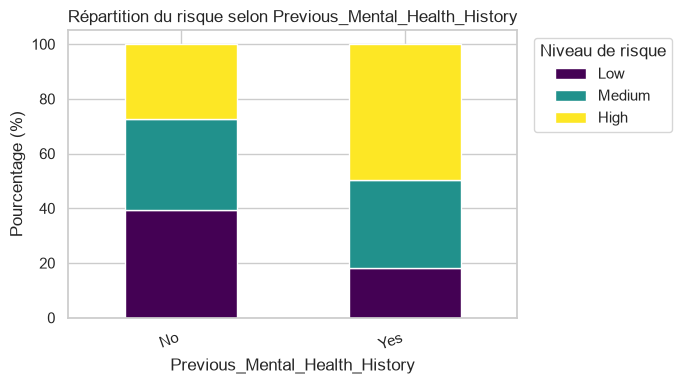

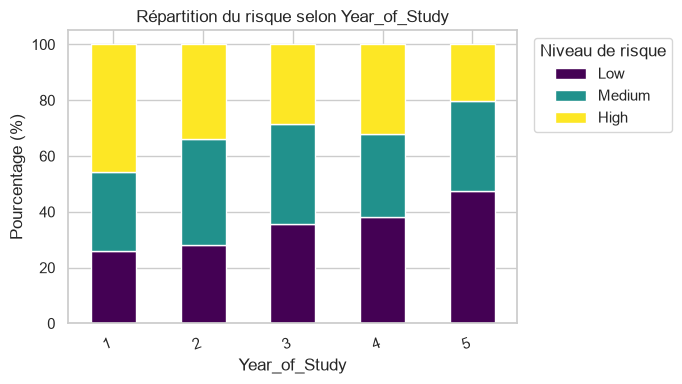

In [8]:
for column in continuous_columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=student_df, x=target, y=column, order=risk_order)
    plt.title(f'{column} selon le niveau de risque')
    plt.xlabel('Niveau de risque')
    plt.tight_layout()
    plt.show()
    plt.close()

categorical_features = [
    column for column in categorical_columns
    if column != target
]
if 'Year_of_Study' in student_df.columns:
    categorical_features.append('Year_of_Study')

for column in categorical_features:
    proportions = pd.crosstab(
        student_df[column], student_df[target], normalize='index'
    ).reindex(columns=risk_order, fill_value=0) * 100
    proportions.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
    plt.title(f'Répartition du risque selon {column}')
    plt.xlabel(column)
    plt.ylabel('Pourcentage (%)')
    plt.legend(title='Niveau de risque', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.xticks(rotation=20, ha='right')
    plt.tight_layout()
    plt.show()
    plt.close()

## 7. Corrélations entre variables numériques

La corrélation de Pearson mesure les relations linéaires entre variables numériques. Elle n'inclut pas la cible catégorielle et ne signifie pas causalité.

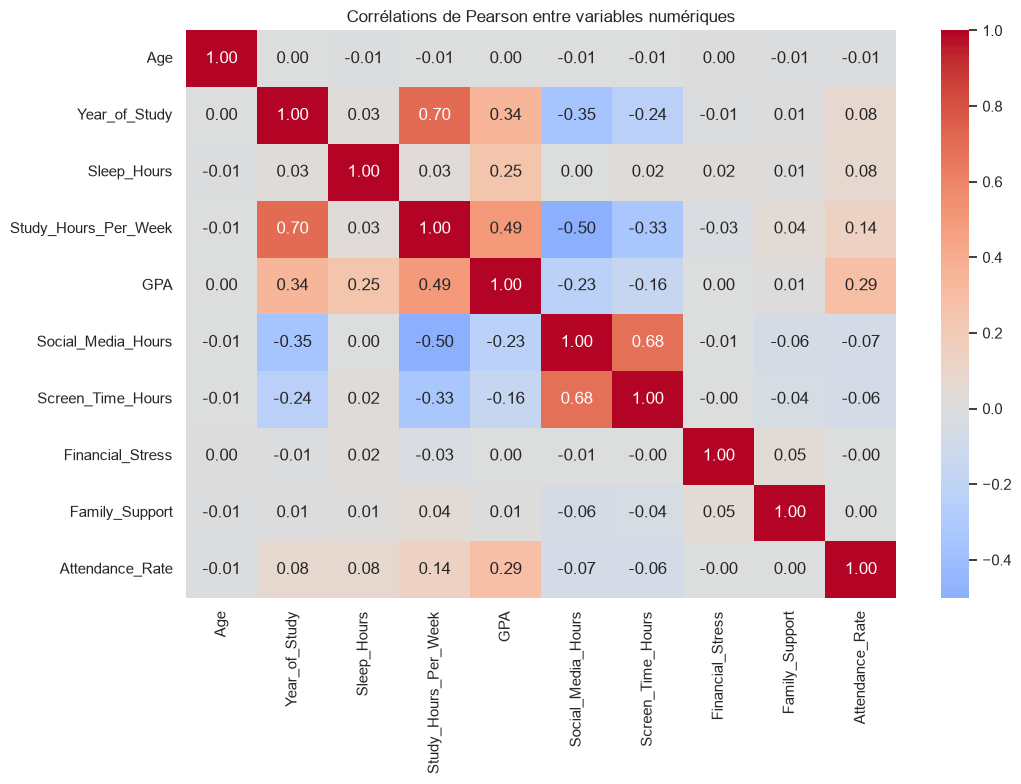

In [9]:
correlation_matrix = student_df.select_dtypes(include='number').corr()
plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Corrélations de Pearson entre variables numériques')
plt.tight_layout()
plt.show()

## 8. Variables les plus associées au niveau de risque

Pour les variables numériques, η² résume la part de variation associée aux différences entre groupes de risque. Pour les variables catégorielles, V de Cramér résume l'association entre catégories et niveau de risque. Les classements sont séparés par type de variable; ils indiquent des associations descriptives, pas des causes.

In [10]:
def eta_squared_by_group(data, feature, group):
    paired = data[[feature, group]].dropna()
    if paired.empty:
        return np.nan
    overall_mean = paired[feature].mean()
    total_sum_squares = ((paired[feature] - overall_mean) ** 2).sum()
    if total_sum_squares == 0:
        return 0.0
    between_sum_squares = sum(
        len(values) * (values.mean() - overall_mean) ** 2
        for _, values in paired.groupby(group)[feature]
    )
    return between_sum_squares / total_sum_squares


def cramers_v(data, feature, group):
    paired = data[[feature, group]].dropna()
    table = pd.crosstab(paired[feature], paired[group])
    if table.empty or min(table.shape) < 2:
        return np.nan
    observed = table.to_numpy(dtype=float)
    total = observed.sum()
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / total
    chi_squared = ((observed - expected) ** 2 / expected).sum()
    return np.sqrt(chi_squared / (total * min(table.shape[0] - 1, table.shape[1] - 1)))


numeric_associations = pd.Series(
    {column: eta_squared_by_group(student_df, column, target) for column in continuous_columns},
    name='eta_squared'
).sort_values(ascending=False)
categorical_associations = pd.Series(
    {column: cramers_v(student_df, column, target) for column in categorical_features},
    name='cramers_v'
).sort_values(ascending=False)

print('Associations avec le risque — variables numériques (η²) :')
display(numeric_associations.to_frame())
print('Associations avec le risque — variables catégorielles (V de Cramér) :')
display(categorical_associations.to_frame())
print('Ces mesures décrivent des associations; elles ne démontrent pas de causalité.')

Associations avec le risque — variables numériques (η²) :


,eta_squared
Sleep_Hours,0.294043
GPA,0.124937
Financial_Stress,0.098628
Family_Support,0.062950
Study_Hours_Per_Week,0.057039
Social_Media_Hours,0.045982
Screen_Time_Hours,0.033268
Attendance_Rate,0.021216
Age,0.000042


Associations avec le risque — variables catégorielles (V de Cramér) :


,cramers_v
Previous_Mental_Health_History,0.242462
Physical_Activity,0.167263
Year_of_Study,0.135031
Part_Time_Job,0.115542
Diet_Quality,0.112518
Gender,0.035717


Ces mesures décrivent des associations; elles ne démontrent pas de causalité.
